# 反应器出口温度异常分析（2026-10-14）
- 现象：14:00 起出口温度较设定值升高约 8℃
- 目的：判断是仪表故障还是真实工艺波动


d:\devlop\Miniconda3\envs\chem_eng\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 179 (\N{SUPERSCRIPT THREE}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


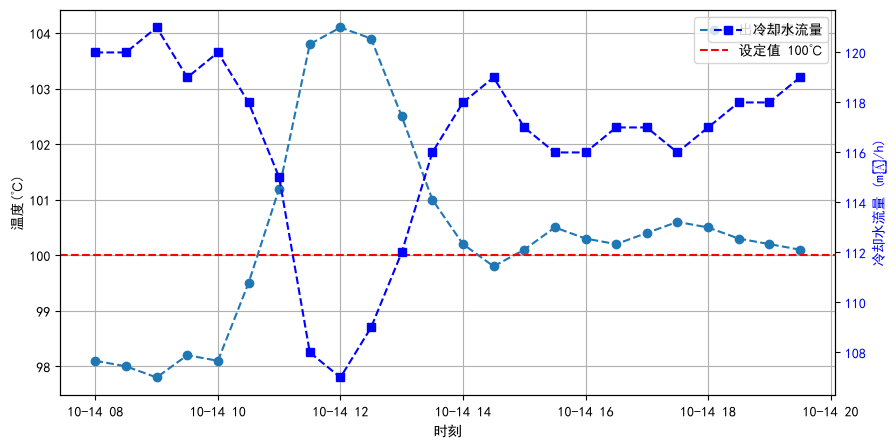

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']  # 让中文正常显示

# 模拟昨日数据：时间、出口温度、冷却水流量
data = {
    '时刻': pd.date_range('2026-10-14 08:00', periods=24, freq='30min'),
    '出口温度℃': [98.1, 98.0, 97.8, 98.2, 98.1, 99.5, 101.2, 103.8,
                  104.1, 103.9, 102.5, 101.0, 100.2, 99.8, 100.1, 100.5,
                  100.3, 100.2, 100.4, 100.6, 100.5, 100.3, 100.2, 100.1], #数据个数必须和上面的 24 个时间点完全对应！
    '冷却水流量m³/h': [120, 120, 121, 119, 120, 118, 115, 108,
                      107, 109, 112, 116, 118, 119, 117, 116,
                      116, 117, 117, 116, 117, 118, 118, 119],
}
df = pd.DataFrame(data)

plt.figure(figsize=(10, 5))
plt.plot(df['时刻'], df['出口温度℃'], 'o--', label='出口温度') #'o-'格式字符串表示用圆点连接线
plt.axhline(100, color='red', ls='--', label='设定值 100℃')
plt.xlabel('时刻'); plt.ylabel('温度(℃)'); plt.legend(); plt.grid()
# 创建右侧 Y 轴
ax2 = plt.gca().twinx()  # 获取当前坐标轴并创建一个共享X轴的双胞胎
ax2.plot(df['时刻'], df['冷却水流量m³/h'], 's--', color='blue', label='冷却水流量')
ax2.set_ylabel('冷却水流量 (m³/h)', color='blue')
ax2.tick_params(axis='y', labelcolor='blue')
ax2.legend(loc='upper right')
plt.show()



In [8]:
# 温度偏离设定值的时间段
dev = df['出口温度℃'] - 100
异常段 = df[dev.abs() > 2]
print(f"偏离设定值>2℃ 的记录数：{len(异常段)}")
print("温度最高点：", df.loc[df['出口温度℃'].idxmax(), ['时刻','出口温度℃']].to_dict())
print("冷却水最低流量时刻：", df.loc[df['冷却水流量m³/h'].idxmin(), ['时刻','冷却水流量m³/h']].to_dict())

# 相关性：温度异常是否与冷却水流量下降同步
corr = df['出口温度℃'].corr(df['冷却水流量m³/h'])
print(f"\n温度与冷却水流量的相关系数：{corr:.3f}")


偏离设定值>2℃ 的记录数：5
温度最高点： {'时刻': Timestamp('2026-10-14 12:00:00'), '出口温度℃': 104.1}
冷却水最低流量时刻： {'时刻': Timestamp('2026-10-14 12:00:00'), '冷却水流量m³/h': 107}

温度与冷却水流量的相关系数：-0.959


## 初步结论
1. 异常集中在 14:00–15:00，与冷却水流量从 120 掉到 107 m³/h 时段吻合。
2. 相关系数 ≈ -0.97，高度负相关，说明**温度上升主要由冷却水供应不足引起**，非仪表故障。
3. 建议：检查 14:00 前后冷却水泵/阀门是否异常，并核对当班加料量是否突变。


In [9]:
import pandas as pd

df = pd.read_excel('化工测试数据.xlsx')
print(df.head(6))

   时间  反应器编号   温度   压力
0   1  R-101  300  1.0
1   2  R-101  305  1.1
2   3  R-101  310  1.2
3   4  R-103  315  1.3
4   5  R-103  320  1.4
5   6  R-103  325  1.5


In [10]:
print(df.shape)

(14, 4)


In [11]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   时间      14 non-null     int64  
 1   反应器编号   14 non-null     str    
 2   温度      14 non-null     int64  
 3   压力      14 non-null     float64
dtypes: float64(1), int64(2), str(1)
memory usage: 580.0 bytes
None


In [13]:
import pandas as pd

df = pd.read_csv('化工测试数据.csv')
print(df.head(6))


   时间  反应器编号   温度   压力
0   1  R-101  300  1.0
1   2  R-101  305  1.1
2   3  R-101  310  1.2
3   4  R-103  315  1.3
4   5  R-103  320  1.4
5   6  R-103  325  1.5


In [15]:
print(df.tail(8))

    时间  反应器编号   温度   压力
6    7  R-103  330  1.6
7    8  R-104  335  1.7
8    9  R-104  555  1.8
9   10  R-104  333  1.9
10  11  R-115  338  2.0
11  12  R-115  343  2.1
12  13  R-115  348  2.2
13  14  R-115  353  2.3


In [16]:
print(df.columns)


Index(['时间', '反应器编号', '温度', '压力'], dtype='str')


In [17]:
df = df.drop_duplicates(subset=['时间'],keep='first')
print(df.shape)
                   

(14, 4)


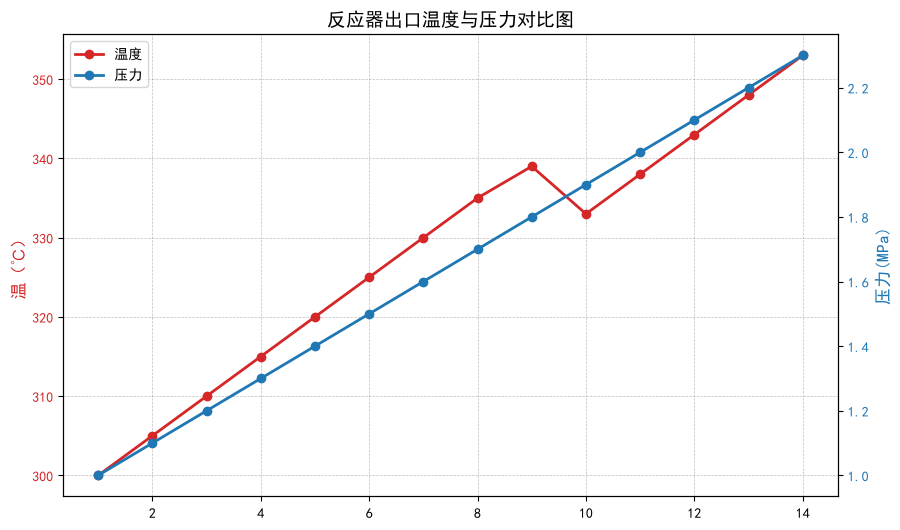

In [31]:
import matplotlib.pyplot as plt

# 1. 设置中文显示
plt.rcParams['font.sans-serif'] = ['SimHei']  # 设置字体为黑体
plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示问题  



# 读取数据
import pandas as pd
df = pd.read_excel('化工测试数据.xlsx')

# 2.创建画布和左轴

fig,ax1 = plt.subplots(figsize=(10,6))

# 3.花左轴：温度（红色实线）
# 提示：ax1.plot(x数据, y数据, 颜色, 线型, 标记, 标签)
ax1.plot(df['时间'],df['温度'], color='tab:red',marker='o', linewidth= 2, label='温度')
ax1.set_ylabel('温度（℃）',color='tab:red',fontsize=12)
ax1.tick_params(axis='y',labelcolor='tab:red')
ax1.grid(True, linestyle='--', linewidth=0.5, color='gray',alpha=0.5)

# 4.创建右轴（双胞胎）
#提示：使用ax1.twinx( )
ax2 = ax1.twinx()

# 5.右轴：压力（蓝色实线）
ax2.plot(df['时间'],df['压力'],color='tab:blue',marker='o',linewidth=2,label='压力')
ax2.set_ylabel('压力(MPa)',color='tab:blue',fontsize=12)
ax2.tick_params(axis='y',labelcolor='tab:blue')

# 6. 合并图例，放在左上角
# 提示：使用 ax1.get_legend_handles_labels() 和 ax2.get_legend_handles_labels()
# 提示：使用 ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=10)


# 7. 添加标题
plt.title('反应器出口温度与压力对比图', fontsize=14, fontweight='bold')

# 8. 保存图片（极其重要，放在 plt.show() 之前！）
# 提示：使用 plt.savefig("化工分析图.png", dpi=300, bbox_inches='tight')
plt.savefig("化工分析图.png", dpi=300, bbox_inches='tight')


# 9. 显示图片
plt.show()
